In [4]:
%%capture
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import warnings
warnings.filterwarnings('ignore')

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Part 2: Define Dataset Paths

In [3]:
# Kaggle sometimes mounts the dataset in one of two places, so I check which one exists
path_1 = "/kaggle/input/vegetable-image-dataset/Vegetable Images"
path_2 = "/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images"

if os.path.exists(path_1):
    base_path = path_1
else:
    base_path = path_2

train_path = base_path + "/train"
test_path = base_path + "/test"
val_path = base_path + "/validation"

print(train_path)
print(test_path)
print(val_path)

/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/train
/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/test
/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/validation


# Part 3: Count Images in Each Class

In [4]:
def count_images(folder_path):
    counts = {}
    for class_name in sorted(os.listdir(folder_path)):
        class_folder = folder_path + "/" + class_name
        if os.path.isdir(class_folder):
            counts[class_name] = len(os.listdir(class_folder))
    return counts

In [5]:
train_counts = count_images(train_path)
test_counts = count_images(test_path)
val_counts = count_images(val_path)

print("Train:", train_counts)
print()
print("Test:", test_counts)
print()
print("Validation:", val_counts)

Train: {'Bean': 1000, 'Bitter_Gourd': 1000, 'Bottle_Gourd': 1000, 'Brinjal': 1000, 'Broccoli': 1000, 'Cabbage': 1000, 'Capsicum': 1000, 'Carrot': 1000, 'Cauliflower': 1000, 'Cucumber': 1000, 'Papaya': 1000, 'Potato': 1000, 'Pumpkin': 1000, 'Radish': 1000, 'Tomato': 1000}

Test: {'Bean': 200, 'Bitter_Gourd': 200, 'Bottle_Gourd': 200, 'Brinjal': 200, 'Broccoli': 200, 'Cabbage': 200, 'Capsicum': 200, 'Carrot': 200, 'Cauliflower': 200, 'Cucumber': 200, 'Papaya': 200, 'Potato': 200, 'Pumpkin': 200, 'Radish': 200, 'Tomato': 200}

Validation: {'Bean': 200, 'Bitter_Gourd': 200, 'Bottle_Gourd': 200, 'Brinjal': 200, 'Broccoli': 200, 'Cabbage': 200, 'Capsicum': 200, 'Carrot': 200, 'Cauliflower': 200, 'Cucumber': 200, 'Papaya': 200, 'Potato': 200, 'Pumpkin': 200, 'Radish': 200, 'Tomato': 200}


# Part 4: Create a Summary DataFrame

In [6]:
train_df = pd.DataFrame(list(train_counts.items()), columns=["Vegetable", "Train Count"])
test_df = pd.DataFrame(list(test_counts.items()), columns=["Vegetable", "Test Count"])
val_df = pd.DataFrame(list(val_counts.items()), columns=["Vegetable", "Validation Count"])

print(train_df.head())
print(test_df.head())
print(val_df.head())

      Vegetable  Train Count
0          Bean         1000
1  Bitter_Gourd         1000
2  Bottle_Gourd         1000
3       Brinjal         1000
4      Broccoli         1000
      Vegetable  Test Count
0          Bean         200
1  Bitter_Gourd         200
2  Bottle_Gourd         200
3       Brinjal         200
4      Broccoli         200
      Vegetable  Validation Count
0          Bean               200
1  Bitter_Gourd               200
2  Bottle_Gourd               200
3       Brinjal               200
4      Broccoli               200


In [7]:
summary_df = train_df.merge(test_df, on="Vegetable").merge(val_df, on="Vegetable")
summary_df

,Vegetable,Train Count,Test Count,Validation Count
0,Bean,1000,200,200
1,Bitter_Gourd,1000,200,200
2,Bottle_Gourd,1000,200,200
3,Brinjal,1000,200,200
4,Broccoli,1000,200,200
5,Cabbage,1000,200,200
6,Capsicum,1000,200,200
7,Carrot,1000,200,200
8,Cauliflower,1000,200,200
9,Cucumber,1000,200,200


# Part 5: Visualize Class Distribution

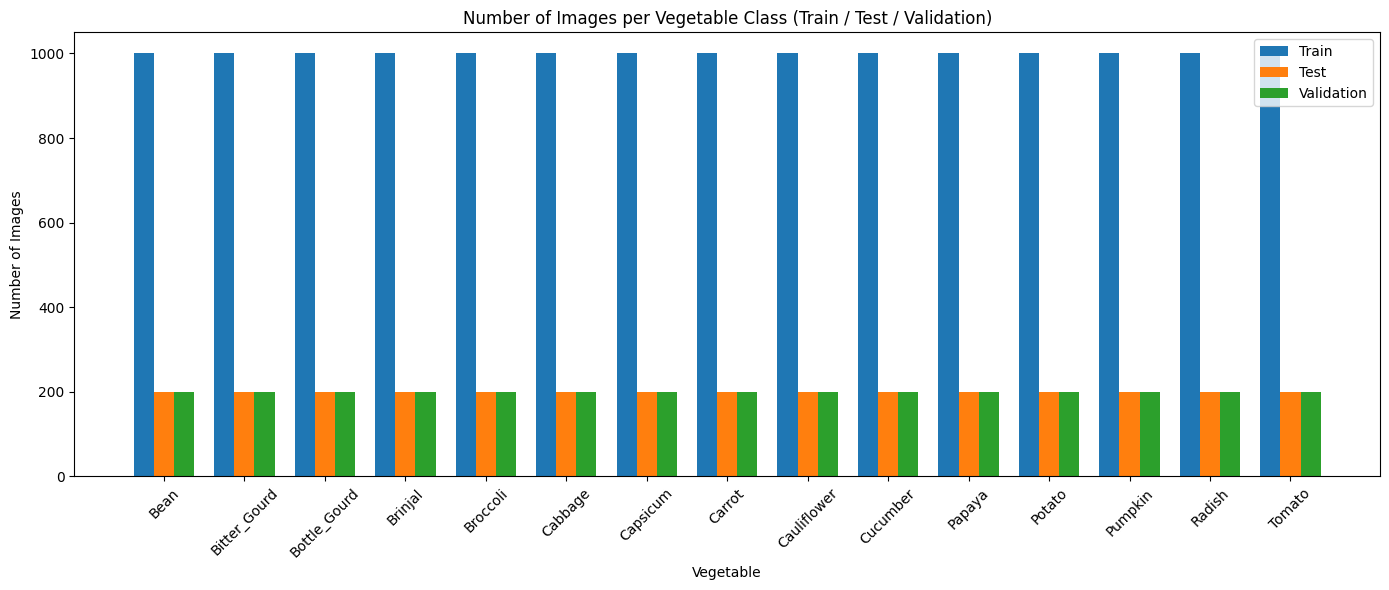

In [8]:
x = np.arange(len(summary_df))   # one position for each vegetable
width = 0.25                     # width of each bar

plt.figure(figsize=(14, 6))
plt.bar(x - width, summary_df["Train Count"], width, label="Train")
plt.bar(x, summary_df["Test Count"], width, label="Test")
plt.bar(x + width, summary_df["Validation Count"], width, label="Validation")

plt.xticks(x, summary_df["Vegetable"], rotation=45)
plt.xlabel("Vegetable")
plt.ylabel("Number of Images")
plt.title("Number of Images per Vegetable Class (Train / Test / Validation)")
plt.legend()
plt.tight_layout()
plt.show()

Yes, the dataset is balanced. In the chart, all 15 vegetables have bars of the same height inside each split:
every class has the same number of images in train, the same number in test, and the same number in validation.
The three splits have different sizes from each other (train is the biggest), but that is normal because it is just the split ratio.
Because no class has more images than the others, the model will not be biased toward one vegetable, and accuracy is a fair metric to use here.

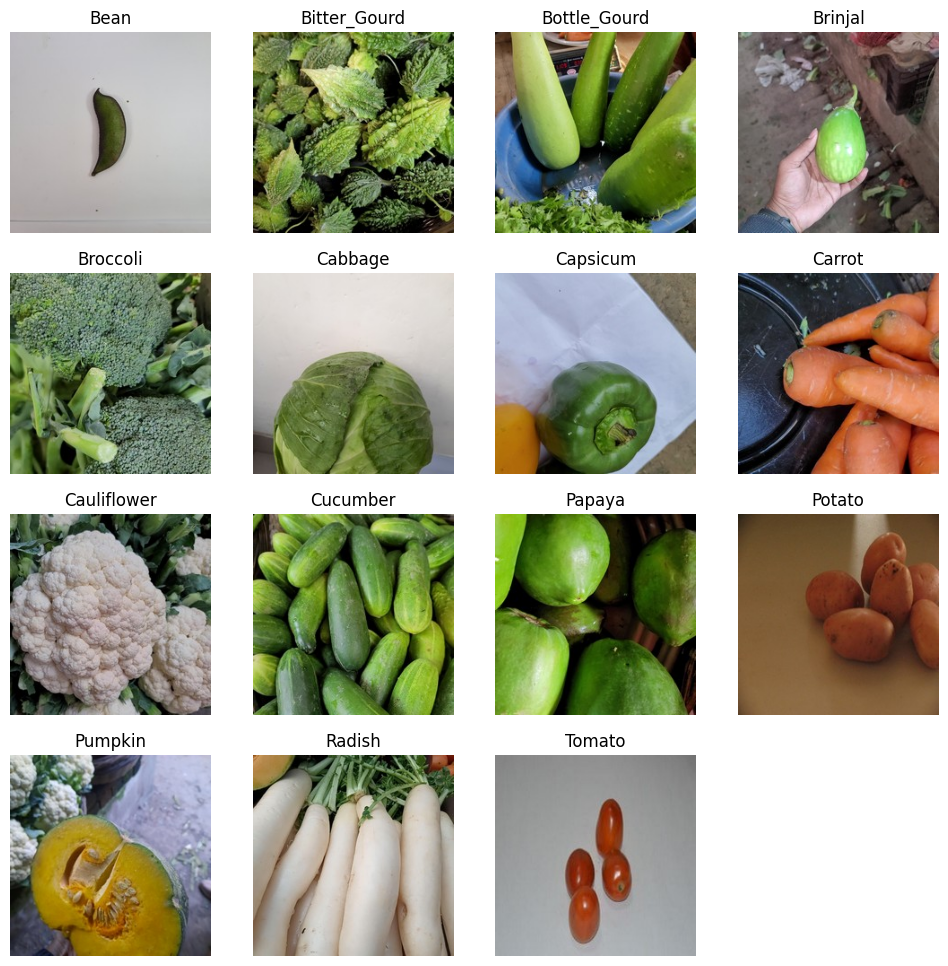

In [9]:
from tensorflow.keras.preprocessing import image

img_classes = sorted(os.listdir(train_path))

plt.figure(figsize=(12, 12))
for i, cat in enumerate(img_classes):
    folder = train_path + "/" + cat
    first_img = os.listdir(folder)[0]
    img_ = image.load_img(folder + "/" + first_img)
    plt.subplot(4, 4, i + 1)
    plt.imshow(img_)
    plt.title(cat)
    plt.axis("off")
plt.show()

# Part 6: Image Preprocessing and Augmentation

In [10]:
train_datagen = ImageDataGenerator(
    rescale=1/255,
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True,
    validation_split=0.2
)

val_datagen = ImageDataGenerator(
    rescale=1/255,
    validation_split=0.2
)

# Part 7: Load Images Using flow_from_directory

In [11]:
train_ds = train_datagen.flow_from_directory(
    train_path,
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
    subset="training",
    seed=42
)

val_ds = val_datagen.flow_from_directory(
    train_path,
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
    subset="validation",
    seed=42
)

Found 12000 images belonging to 15 classes.
Found 3000 images belonging to 15 classes.


In [12]:
print(train_ds.class_indices)

{'Bean': 0, 'Bitter_Gourd': 1, 'Bottle_Gourd': 2, 'Brinjal': 3, 'Broccoli': 4, 'Cabbage': 5, 'Capsicum': 6, 'Carrot': 7, 'Cauliflower': 8, 'Cucumber': 9, 'Papaya': 10, 'Potato': 11, 'Pumpkin': 12, 'Radish': 13, 'Tomato': 14}


# Part 8: Build the CNN Model

In [13]:
model = Sequential()

# Convolution Block 1
model.add(Conv2D(32, (3, 3), activation="relu", input_shape=(224, 224, 3)))
model.add(MaxPooling2D(pool_size=(2, 2)))

# Convolution Block 2
model.add(Conv2D(64, (3, 3), activation="relu"))
model.add(MaxPooling2D(pool_size=(2, 2)))

# Convolution Block 3
model.add(Conv2D(128, (3, 3), activation="relu"))
model.add(MaxPooling2D(pool_size=(2, 2)))

# Fully Connected Layers
model.add(Flatten())
model.add(Dense(512, activation="relu"))
model.add(Dropout(0.5))

# Output layer (15 classes)
model.add(Dense(15, activation="softmax"))

# Part 9: Compile the Model

In [14]:
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [15]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    44,302,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 15)             │         7,695 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,403,791 (169.39 MB)

 Trainable params: 44,403,791 (169.39 MB)

 Non-trainable params: 0 (0.00 B)

**Model explanation**

1. **Number of convolutional layers:** 3 (with 32, 64 and 128 filters). Each one is followed by a max pooling layer.
2. **Purpose of pooling layers:** MaxPooling reduces the height and width of the feature maps (here by half each time). This makes the model smaller and faster, reduces the number of parameters, and keeps the strongest features so small shifts in the image matter less.
3. **Purpose of dropout:** Dropout randomly turns off 50% of the neurons in the dense layer during training. This stops the neurons from depending on each other too much, so the model memorizes the training data less (reduces overfitting).
4. **Why softmax in the output layer:** Softmax turns the 15 output values into probabilities that add up to 1. This is what we need for multi-class classification, where each image belongs to exactly one class, and the biggest probability is the predicted vegetable.

# Part 10: Train the Model

In [16]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

In [17]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[early_stop]
)

Epoch 1/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 803s 2s/step - accuracy: 0.4891 - loss: 1.5397 - val_accuracy: 0.7347 - val_loss: 0.7558
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 171s 454ms/step - accuracy: 0.7310 - loss: 0.8220 - val_accuracy: 0.8377 - val_loss: 0.5081
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 173s 461ms/step - accuracy: 0.8130 - loss: 0.5814 - val_accuracy: 0.8867 - val_loss: 0.3453
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 170s 453ms/step - accuracy: 0.8531 - loss: 0.4609 - val_accuracy: 0.9043 - val_loss: 0.2809
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 168s 449ms/step - accuracy: 0.8709 - loss: 0.4082 - val_accuracy: 0.9323 - val_loss: 0.2334
Epoch 6/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 170s 454ms/step - accuracy: 0.8852 - loss: 0.3579 - val_accuracy: 0.9427 - val_loss: 0.1836
Epoch 7/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 171s 457ms/step - accuracy: 0.8966 - loss: 0.3254 - val_accuracy: 0.9503 - val_loss: 0.1694
Epoch 8/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 169s 450ms/step - accuracy: 0.9115 - lo

EarlyStopping watches the validation loss and stops the training when it has not improved for 5 epochs in a row.
This saves time, and it prevents overfitting, because if we keep training after the validation loss starts going up the model only memorizes the training images.
With restore_best_weights=True, the model also goes back to the weights from the best epoch instead of keeping the weights from the last (worse) epoch.

# Part 11: Evaluate the Model

In [18]:
train_loss, train_acc = model.evaluate(train_ds)
val_loss, val_acc = model.evaluate(val_ds)

print("Training Accuracy:   ", round(train_acc, 4))
print("Validation Accuracy: ", round(val_acc, 4))
print("Training Loss:       ", round(train_loss, 4))
print("Validation Loss:     ", round(val_loss, 4))

375/375 ━━━━━━━━━━━━━━━━━━━━ 145s 387ms/step - accuracy: 0.9843 - loss: 0.0510
94/94 ━━━━━━━━━━━━━━━━━━━━ 8s 87ms/step - accuracy: 0.9833 - loss: 0.0660
Training Accuracy:    0.9843
Validation Accuracy:  0.9833
Training Loss:        0.051
Validation Loss:      0.066


In [19]:
print("Accuracy difference (train - validation):", round(train_acc - val_acc, 4))
print("Loss difference (validation - train):    ", round(val_loss - train_loss, 4))

Accuracy difference (train - validation): 0.0009
Loss difference (validation - train):     0.015


No, there is no large difference. The training accuracy is 0.9843 (98.43%) and the validation accuracy is 0.9833 (98.33%), so the gap is only about 0.001 (0.1%). The training loss is 0.051 and the validation loss is 0.066, a difference of only 0.015.

Both accuracies are very high and almost identical, so the model is not overfitting. It performs just as well on images it did not train on as on the training images, which means it generalizes well and is not just memorizing the training set. This is expected, because I used data augmentation, dropout (0.5), and EarlyStopping with restore_best_weights, which all help to reduce overfitting.

# Part 12: Plot Accuracy and Loss Curves

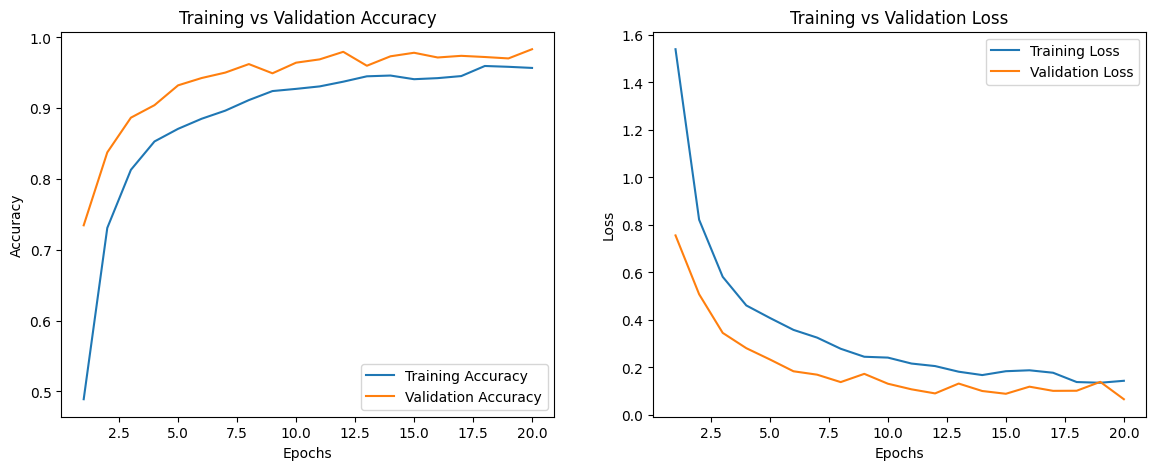

In [20]:
epochs_range = range(1, len(history.history["accuracy"]) + 1)

plt.figure(figsize=(14, 5))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history.history["accuracy"], label="Training Accuracy")
plt.plot(epochs_range, history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Training vs Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history.history["loss"], label="Training Loss")
plt.plot(epochs_range, history.history["val_loss"], label="Validation Loss")
plt.title("Training vs Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.show()